In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

from src.load_uci import load_uci_inertial
from src.features import extract_features
from src.results_log import log_run, load_log

X_train_windows, meta_train = load_uci_inertial("train")
X_test_windows, meta_test = load_uci_inertial("test")

X_train, y_train = extract_features(X_train_windows), meta_train["activity"]
X_test, y_test = extract_features(X_test_windows), meta_test["activity"]

In [2]:
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

predictions = rf.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
print(f"Macro F1: {f1_score(y_test, predictions, average='macro'):.3f}\n")
print(classification_report(y_test, predictions, digits=3))

run_folder = log_run("Random Forest", "UCI train", "UCI test",
                     y_train, y_test, predictions, notes="first RF run on UCI dataset")

Accuracy: 0.885
Macro F1: 0.885

                    precision    recall  f1-score   support

           walking      0.866     0.913     0.889       496
walking_downstairs      0.946     0.833     0.886       420
  walking_upstairs      0.860     0.902     0.881       471

          accuracy                          0.885      1387
         macro avg      0.891     0.883     0.885      1387
      weighted avg      0.888     0.885     0.885      1387

Logged run 2026-10-13_16-31-27  (accuracy 0.8854, macro F1 0.8853)


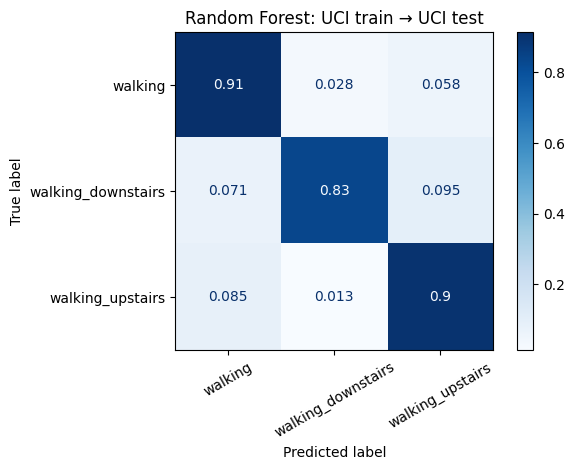

In [3]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions, normalize="true",
                                        cmap="Blues", xticks_rotation=30)
plt.title("Random Forest: UCI train → UCI test")
plt.tight_layout()
plt.savefig(run_folder / "confusion_matrix.png", dpi=150)
plt.show()

In [4]:
load_log()

,run_id,model,train_data,test_data,train_windows,test_windows,train_walking,train_walking_upstairs,train_walking_downstairs,accuracy,macro_f1,f1_walking,f1_walking_upstairs,f1_walking_downstairs,notes
0,2026-10-13_16-02-57,Random Forest,UCI train,UCI test,3285,1387,1226,1073,986,0.8854,0.8853,0.8891,0.8808,0.8861,first model on uci dataset
1,2026-10-13_16-29-55,Logistic Regression,UCI train,UCI test,3285,1387,1226,1073,986,0.8709,0.8701,0.8830,0.8539,0.8734,no pipeline
2,2026-10-13_16-30-52,Logistic Regression,UCI train,UCI test,3285,1387,1226,1073,986,0.8709,0.8701,0.8830,0.8539,0.8734,first LR run on UCI dataset
3,2026-10-13_16-31-27,Random Forest,UCI train,UCI test,3285,1387,1226,1073,986,0.8854,0.8853,0.8891,0.8808,0.8861,first RF run on UCI dataset
